# Crowding: how much of each ELK aperture's light is the cluster?

The correlation analysis (`Correlation_Analysis/`) found one weak but significant trend:
younger clusters have larger *fractional* variability amplitudes (partial Spearman
ρ ≈ −0.26, ~4.5σ). None of its nine nuisances measures crowding. ELK
([Wainer et al. 2023](https://arxiv.org/abs/2307.09510)) sums every pixel inside the catalogue
radius. Its correction regresses out *time-variable* systematics (principal components of
the background pixels, CBVs), so constant field light can survive in the median flux, which
every normalised statistic divides by.

This notebook estimates, for every cluster and to order of magnitude,

$$ f_{\rm cl} \;=\; \frac{F_{\rm cluster}}{F_{\rm aperture}} $$

and asks whether it depends on age. Adding crowding or position to the nuisance models is a
separate, later step; this notebook only characterises the light budget.

## 0 · Physics

**What the statistics see.** The aperture flux is
$F_{\rm tot} = F_{\rm cl} + F_{\rm field} + F_{\rm sky}$. A fractional statistic is
$\sigma_{\rm obs}/\langle F_{\rm tot}\rangle$ with

$$ \sigma^2_{\rm obs} = f_{\rm cl}^2\, a^2_{\rm cl} + \sum_{i\,\in\,\rm field} \Big(\frac{F_i}{F_{\rm tot}}\Big)^2 a_i^2 + \text{noise}, $$

where $a$ is an intrinsic fractional amplitude. Two effects follow:
- **Dilution:** $\log a_{\rm obs} = \log a_{\rm cl} + \log f_{\rm cl}$ when the field is quiet.
- **Contamination:** variable field stars add variance unrelated to the cluster.

**Why dilution would track age.**

$$ \frac{f_{\rm cl}}{1-f_{\rm cl}} \approx \frac{M_{\rm cl}\,\Upsilon_T(t)^{-1}\,10^{-0.4(\mu + A_T)}}{\Sigma_{\rm field}\,A_{\rm ap}} $$

The TESS-band mass-to-light ratio $\Upsilon_T$ rises ~6× between 10 Myr and 1 Gyr (~35× by
10 Gyr; Section 2). At fixed
mass, an older cluster is fainter, more diluted, and so less variable *as measured*. That is
the same sign as the observed trend. Sample selection (star counts, brightness) partly
offsets it, so $f_{\rm cl}$ has to be measured.

**Three independent pieces, then a closure test.**

| Piece | Route | Notes |
|---|---|---|
| Cluster light | **Literature integrated photometry** (primary): Glatt+2010 (LMC, SMC <1 Gyr; field-subtracted, same radius as ELK), Rafelski & Zaritsky 2005 (other SMC), Kharchenko+2016 (MW, same MWSC radius). Converted to T with PARSEC SSP colours at the cluster age. | Observed magnitudes, so extinction largely cancels. |
| | **Mass × SSP light per M☉**: Popescu+2012 (LMC), Hunt & Reffert 2024 (MW) | Expected light; differs from the realised light by stochastic sampling for M ≲ 10⁴ M☉. |
| | **Gaia statistical subtraction** (MW): flux in r_ap minus annulus field | Membership-free. |
| Field light A | Smooth model vs position: inclined LMC disk, SMC exponential, MW line-of-sight integral with dust | Misses structure, especially the young star-forming fields young clusters live in. |
| Field light B | Gaia DR3 annulus surface brightness × aperture area | Resolved sources only (G ≲ 20.7); incomplete in crowded MC fields. |
| Sky | Zodiacal light vs ecliptic latitude | Only matters if ELK's median flux kept it. |
| **Closure** | $F_{\rm meas}$ vs $F_{\rm cl}+F_{\rm field}$ | Decides whether the field pedestal is in the light curve. |

A uniform field keeps its surface brightness under PSF convolution, so the expected field flux
is $\mu_{\rm field}A_{\rm ap}$ exactly. The PSF only matters for (i) cluster light leaking out of
the small MC apertures and (ii) individual bright stars near the aperture edge.

In [1]:
%load_ext autoreload
%autoreload 2
import os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
warnings.filterwarnings('ignore', category=RuntimeWarning)

HERE = os.path.abspath('.')
sys.path.insert(0, HERE)
from crowd import T_ZP, mag_to_flux, flux_to_mag
from crowd import catalogs as C, ssp as S, galaxy_models as M, gaia_field as G, budget as B

FIG = os.path.join(HERE, 'figs'); os.makedirs(FIG, exist_ok=True)
GAL = ['MW', 'LMC', 'SMC']
COL = {'MW': '#2a78d6', 'LMC': '#eb6834', 'SMC': '#1baf7a'}   # same hues as Correlation_Analysis
MRK = {'MW': 'o', 'LMC': 's', 'SMC': '^'}                       # secondary encoding
INK, MUTED = '#2c2c2a', '#8f8e88'
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
                     'axes.grid': True, 'grid.color': '#e6e5e0', 'axes.axisbelow': True,
                     'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False,
                     'axes.edgecolor': MUTED, 'axes.labelcolor': INK, 'xtick.color': INK,
                     'ytick.color': INK, 'lines.linewidth': 2})

def save(fig, name):
    fig.savefig(os.path.join(FIG, name), dpi=150, bbox_inches='tight')

## 1 · Clusters and the measured aperture flux

`F_meas` is the median over sectors of each sector's median ELK flux (e/s). The ELK `mag`
column uses T = −2.5 log₁₀ F + 20.44; checking that pins every flux in this notebook to the
same zero point. `sector_spread` is the 16–84% half-range of the per-sector medians divided
by their median. A purely multiplicative effect can't produce it; an additive background
that changes from sector to sector can.

In [2]:
cl0 = C.cluster_list()
zp_check = cl0.T_meas - flux_to_mag(cl0.F_meas)
print(f'{len(cl0)} clusters:', cl0.groupby("origin").size().to_dict())
print(f'ELK zero point check: T_meas - (-2.5 log F + {T_ZP}) = {np.nanmedian(zp_check):+.3f} '
      f'(spread {np.nanstd(zp_check):.3f}; non-zero only through median-of-medians ordering)')
display(cl0.groupby('origin')[['r_ap_arcsec', 'T_meas', 'n_sectors', 'sector_spread']]
        .median().round(2).rename(columns=lambda c: 'median ' + c))

348 clusters: {'LMC': 118, 'MW': 124, 'SMC': 106}
ELK zero point check: T_meas - (-2.5 log F + 20.44) = +0.000 (spread 0.004; non-zero only through median-of-medians ordering)


,median r_ap_arcsec,median T_meas,median n_sectors,median sector_spread
origin,,,,
LMC,45.0,10.87,16.0,0.09
MW,561.6,5.03,2.0,0.02
SMC,60.0,10.31,1.0,0.00


## 2 · Stellar-population models

PARSEC v1.2S single-burst populations (CMD 3.9, Chabrier 2001 lognormal IMF), giving absolute
magnitudes per 1 M☉ of initial mass in TESS + 2MASS and Bessell UBVRI. Metallicities: Z = 0.0152
(MW), 0.008 (LMC), 0.004 (SMC). They provide the colours that move literature V/I/J into the TESS
band at each cluster's age, plus the light per unit mass for the mass route.

,MW,LMC,SMC
M/L_V @ 7,0.06,0.07,0.07
M/L_V @ 8,0.16,0.15,0.15
M/L_V @ 9,0.68,0.59,0.54
M/L_V @ 10,5.60,4.63,3.92
V-T @ 7,0.25,0.26,0.10
V-T @ 8,0.38,0.34,0.38
V-T @ 9,0.67,0.66,0.58
V-T @ 10,1.12,1.04,0.97
T-J @ 7,0.54,0.47,0.25
T-J @ 8,0.61,0.55,0.56


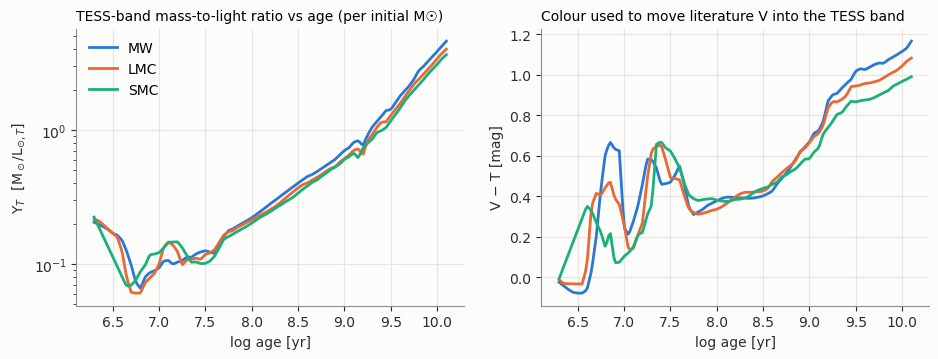

In [3]:
ssp = S.SSP()
ages = np.array([7.0, 8.0, 9.0, 10.0])
chk = pd.DataFrame({o: {f'M/L_V @ {a:.0f}': 10 ** (-0.4 * (4.81 - ssp.mag('V', a, o))) for a in ages}
                    | {f'V-T @ {a:.0f}': ssp.color('V', 'T', a, o) for a in ages}
                    | {f'T-J @ {a:.0f}': ssp.color('T', 'J', a, o) for a in ages} for o in GAL})
display(chk.round(2))

fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
grid = np.linspace(6.3, 10.1, 200)
for o in GAL:
    axs[0].plot(grid, 10 ** (0.4 * (ssp.mag('T', grid, o) - M.M_SUN_T)), color=COL[o], label=o)
    axs[1].plot(grid, ssp.color('V', 'T', grid, o), color=COL[o], label=o)
axs[0].set(yscale='log', xlabel='log age [yr]', ylabel=r'$\Upsilon_T$  [M$_\odot$/L$_{\odot,T}$]')
axs[0].set_title('TESS-band mass-to-light ratio vs age (per initial M☉)', loc='left', fontsize=10)
axs[1].set(xlabel='log age [yr]', ylabel='V − T [mag]')
axs[1].set_title('Colour used to move literature V into the TESS band', loc='left', fontsize=10)
axs[0].legend(); save(fig, 'fig_ssp.png'); plt.show()

In [4]:
y = 10 ** (0.4 * (ssp.mag('T', np.array([7.0, 9.0, 10.0]), 'LMC') - M.M_SUN_T))
print('CONCLUSION —')
print(f'  LMC-metallicity Upsilon_T: {y[0]:.2f} at 10 Myr -> {y[1]:.2f} at 1 Gyr '
      f'(x{y[1]/y[0]:.0f}), {y[2]:.1f} at 10 Gyr (x{y[2]/y[0]:.0f}).  At fixed mass, a 1 Gyr cluster is '
      f'~{2.5*np.log10(y[1]/y[0]):.1f} mag fainter than a 10 Myr one.')
print('  M/L_V at 10 Gyr, solar Z ~ 5-6 and V - T ~ 1.1: in line with standard SSP libraries.')

CONCLUSION —
  LMC-metallicity Upsilon_T: 0.10 at 10 Myr -> 0.61 at 1 Gyr (x6), 3.4 at 10 Gyr (x34).  At fixed mass, a 1 Gyr cluster is ~2.0 mag fainter than a 10 Myr one.
  M/L_V at 10 Gyr, solar Z ~ 5-6 and V - T ~ 1.1: in line with standard SSP libraries.


## 3 · The light budget

`B.build_budget()` assembles everything per cluster. The Gaia queries (radial-ring flux sums
done server-side, plus bright-star rows) and VizieR tables are cached in
`GenerateTable_CGW/data/crowding_cache/`, so this cell is quick after the first run.

**Cluster light in the aperture.** ELK's MW apertures are Kharchenko's r₂ (≫ PSF), so all the
cluster light is collected. The MC apertures are only 2–3 TESS pixels across, so a
Plummer-profile cluster convolved with a Gaussian PSF (σ = 0.75 px) loses light off the edge.
Glatt's photometry counts only light inside R_app (= the ELK radius), so the correction is
(after PSF)/(intrinsic). Rafelski and mass-based values are totals, so the correction is the
after-PSF fraction. The Plummer scale (r_ap/4 to r_ap/2) and PSF width (0.5–1.0 px) are varied
to set a range.

In [5]:
bud = B.build_budget()
bud.to_csv(os.path.join(HERE, 'crowding_budget.csv'), index=False)
cov = bud.groupby('origin').agg(clusters=('name', 'size'),
                                cluster_photometry=('F_cl_phot', lambda x: int(np.isfinite(x).sum())),
                                mass_route=('F_cl_mass', lambda x: int(np.isfinite(x).sum())),
                                median_enclosure=('enc', 'median'))
display(cov.loc[GAL].round(2))
print(bud.groupby('origin').phot_source.value_counts().to_string())

          n  phot  mass
origin                 
LMC     118   118    33
MW      124   124    76
SMC     106    83     0


,clusters,cluster_photometry,mass_route,median_enclosure
origin,,,,
MW,124,124,76,1.00
LMC,118,118,33,0.92
SMC,106,83,0,0.93


origin  phot_source   
LMC     glatt2010         118
MW      kharchenko2016    124
SMC     glatt2010          66
                           23
        rafelski2005       17


### 3a · Do the cluster-light routes agree?

Photometry gives the *realised* light; mass × SSP gives the *expected* light for that mass. For
small clusters the realised value scatters around the expectation, because a handful of
supergiants or giants dominate the light. For the MW, the Gaia statistical subtraction is a
third estimate that doesn't use a membership list.

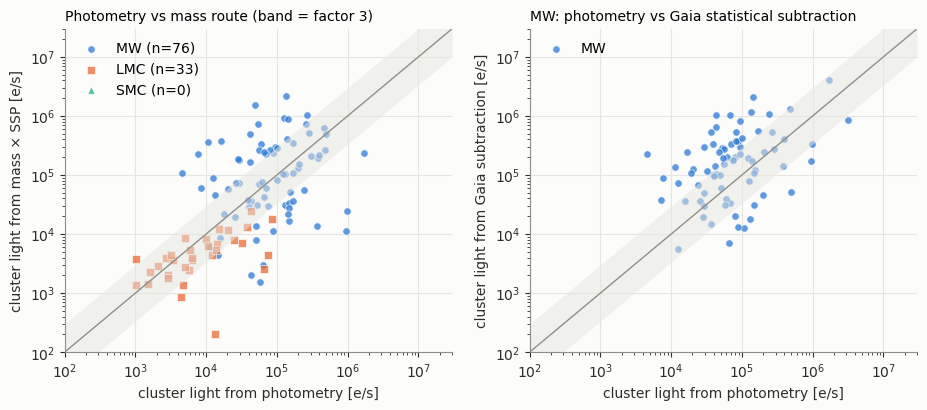

CONCLUSION —
  LMC: log(mass route / photometry) = -0.24 dex, 1-sigma scatter 0.39 dex (n=33)
  MW: log(mass route / photometry) = -0.04 dex, 1-sigma scatter 0.73 dex (n=76)
  MW: log(Gaia subtraction / Kharchenko) = +0.39 dex, scatter 0.66 dex (n=76)
  Scatter of a few tenths of a dex is the expected size of stochastic sampling plus catalogue
  aperture differences; it sets the error bar on f_cl.


In [6]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
for o in GAL:
    d = bud[bud.origin == o]
    axs[0].scatter(d.F_cl_phot, d.F_cl_mass, s=28, marker=MRK[o], color=COL[o], alpha=.75,
                   edgecolor='#fcfcfb', lw=.6, label=f'{o} (n={int((d.F_cl_phot.notna() & d.F_cl_mass.notna()).sum())})')
d = bud[bud.origin == 'MW']
axs[1].scatter(d.F_cl_phot, d.F_cl_gaia.where(d.F_cl_gaia > 0), s=28, marker='o', color=COL['MW'],
               alpha=.75, edgecolor='#fcfcfb', lw=.6, label='MW')
for ax, yl in zip(axs, ['cluster light from mass × SSP [e/s]', 'cluster light from Gaia subtraction [e/s]']):
    lim = np.array([1e2, 3e7])
    ax.plot(lim, lim, color=MUTED, lw=1); ax.fill_between(lim, lim / 3, lim * 3, color='#e6e5e0', alpha=.5, lw=0)
    ax.set(xscale='log', yscale='log', xlim=lim, ylim=lim, xlabel='cluster light from photometry [e/s]', ylabel=yl)
    ax.legend(loc='upper left')
axs[0].set_title('Photometry vs mass route (band = factor 3)', loc='left', fontsize=10)
axs[1].set_title('MW: photometry vs Gaia statistical subtraction', loc='left', fontsize=10)
save(fig, 'fig_cluster_routes.png'); plt.show()

def dex_scatter(a, b):
    r = np.log10(a / b); r = r[np.isfinite(r)]
    return np.median(r), 0.5 * np.subtract(*np.percentile(r, [84, 16])), len(r)
print('CONCLUSION —')
for o in ('LMC', 'MW'):
    d = bud[bud.origin == o]; m, s, n = dex_scatter(d.F_cl_mass, d.F_cl_phot)
    print(f'  {o}: log(mass route / photometry) = {m:+.2f} dex, 1-sigma scatter {s:.2f} dex (n={n})')
m, s, n = dex_scatter(d.F_cl_gaia.where(d.F_cl_gaia > 0), d.F_cl_phot)
print(f'  MW: log(Gaia subtraction / Kharchenko) = {m:+.2f} dex, scatter {s:.2f} dex (n={n})')
print('  Scatter of a few tenths of a dex is the expected size of stochastic sampling plus catalogue')
print('  aperture differences; it sets the error bar on f_cl.')

## 4 · Field light, method A: smooth galaxy models

- **LMC:** inclined exponential disk (centre and geometry from van der Marel & Cioni 2001,
  R_d = 1.5 kpc), normalised to M_V = −18.1. Integrating the model over the sky returns the
  input luminosity, which is checked below.
- **SMC:** projected exponential (R_d = 0.7 kpc), normalised to M_V = −16.8.
- **MW:** line-of-sight integral through thin and thick disks with an exponential dust layer,
  normalised to the local I-band disk surface brightness (~29 L☉ pc⁻²). It is added to every
  sightline, including the MW foreground in front of the Clouds.

The bar, arms and star-forming complexes are deliberately left out, so method A is a smooth
baseline.

LMC model sky integral / input luminosity = 0.998
Model surface brightness [T mag/arcsec^2]:
  LMC centre              20.3
  SMC centre              20.3
  MW, Galactic pole       22.9
  MW, plane l=90          20.7
  MW foreground at LMC    22.1
  zodi, ecliptic pole     22.6


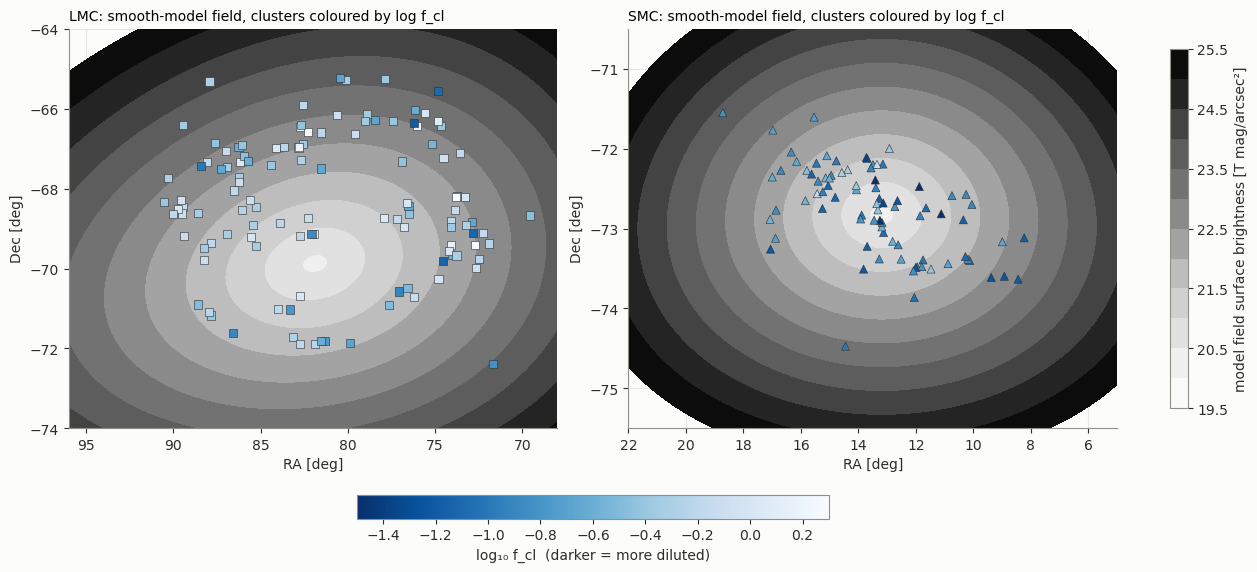

In [7]:
ra = np.linspace(40, 125, 600); dec = np.linspace(-90, -45, 400); RA, DE = np.meshgrid(ra, dec)
sb = M.lmc_sb(RA, DE)
dA = np.radians(ra[1] - ra[0]) * np.cos(np.radians(DE)) * np.radians(dec[1] - dec[0]) / M.ARCSEC2_SR
expected = mag_to_flux(M.LMC['MV'] - M.LMC['V_minus_T'] + 5 * np.log10(M.LMC['D_kpc'] * 1e3 / 10))
print(f'LMC model sky integral / input luminosity = {np.nansum(np.where(sb > 0, sb, 0) * dA) / expected:.3f}')

mu = lambda f: -2.5 * np.log10(f) + T_ZP          # e/s/arcsec^2 -> mag/arcsec^2
print('Model surface brightness [T mag/arcsec^2]:')
for lab, val in [('LMC centre', M.lmc_sb(81.9, -69.87)), ('SMC centre', M.smc_sb(13.19, -72.83)),
                 ('MW, Galactic pole', M.mw_sb(0, 90)), ('MW, plane l=90', M.mw_sb(90, 0)),
                 ('MW foreground at LMC', M.mw_sb(280.5, -32.9)), ('zodi, ecliptic pole', M.zodi_sb(90))]:
    print(f'  {lab:22s} {float(mu(val)):5.1f}')

fig, axs = plt.subplots(1, 2, figsize=(12.5, 5.6), layout='constrained')
for ax, o, fn, (r0, r1, d0, d1) in [(axs[0], 'LMC', M.lmc_sb, (68, 96, -74, -64)),
                                    (axs[1], 'SMC', M.smc_sb, (5, 22, -75.5, -70.5))]:
    gx, gy = np.meshgrid(np.linspace(r0, r1, 300), np.linspace(d0, d1, 200))
    cs = ax.contourf(gx, gy, mu(fn(gx, gy)), levels=np.arange(19.5, 25.6, 0.5), cmap='Greys')
    d = bud[bud.origin == o]
    sc = ax.scatter(d.ra, d.dec, c=np.log10(d.f_cl), cmap='Blues_r', vmin=-1.5, vmax=0.3, s=34,
                    marker=MRK[o], edgecolor=INK, lw=.4)
    ax.invert_xaxis(); ax.set(xlabel='RA [deg]', ylabel='Dec [deg]')
    ax.set_title(f'{o}: smooth-model field, clusters coloured by log f_cl', loc='left', fontsize=10)
fig.colorbar(cs, ax=axs, location='right', shrink=.9, label='model field surface brightness [T mag/arcsec²]')
fig.colorbar(sc, ax=axs, location='bottom', shrink=.45, label='log₁₀ f_cl  (darker = more diluted)')
save(fig, 'fig_mc_maps.png'); plt.show()

## 5 · Field light, method B: Gaia DR3 around each cluster

Gaia flux in rings of 0.25 r_ap out to 5 r_ap (MCs) or 3 r_ap (MW), converted to T with the
Stassun+2019 colour relation. The field surface brightness is the ring flux per area in an
annulus (2–4 r_ap for the MCs, 1.5–2.5 r_ap for the MW) times the aperture area.

Because Gaia resolves only G ≲ 20.7, B/A < 1 is expected in the MCs (unresolved main
sequence). In the MW the comparison tests the smooth disk model.

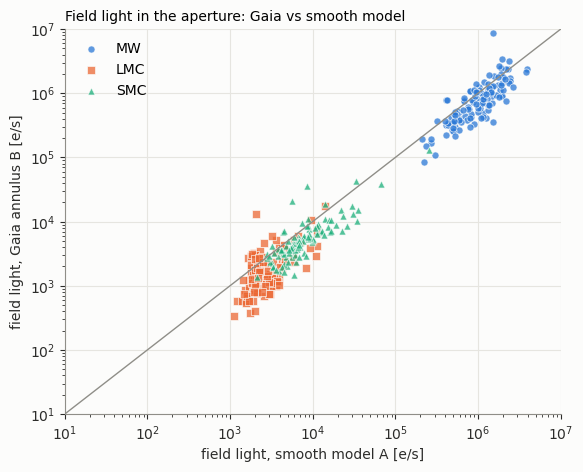

,count,16%,50%,84%
origin,,,,
MW,124.0,0.51,0.74,1.10
LMC,118.0,0.35,0.58,1.03
SMC,106.0,0.47,0.67,0.95


CONCLUSION —
  MW: Gaia field / model field median 0.74 (16-84%: 0.51-1.10)
  LMC: Gaia field / model field median 0.58 (16-84%: 0.35-1.03)
  SMC: Gaia field / model field median 0.67 (16-84%: 0.47-0.95)


In [8]:
fig, ax = plt.subplots(figsize=(6.4, 5))
for o in GAL:
    d = bud[bud.origin == o]
    ax.scatter(d.F_field_A, d.F_field_B, s=26, marker=MRK[o], color=COL[o], alpha=.75,
               edgecolor='#fcfcfb', lw=.6, label=o)
lim = np.array([1e1, 1e7])
ax.plot(lim, lim, color=MUTED, lw=1)
ax.set(xscale='log', yscale='log', xlim=lim, ylim=lim, xlabel='field light, smooth model A [e/s]',
       ylabel='field light, Gaia annulus B [e/s]')
ax.set_title('Field light in the aperture: Gaia vs smooth model', loc='left', fontsize=10)
ax.legend(loc='upper left'); save(fig, 'fig_field_A_vs_B.png'); plt.show()

q = bud.groupby('origin').B_over_A.describe(percentiles=[.16, .5, .84])[['count', '16%', '50%', '84%']]
display(q.loc[GAL].round(2))
print('CONCLUSION —')
for o in GAL:
    v = bud[bud.origin == o].B_over_A
    print(f'  {o}: Gaia field / model field median {v.median():.2f} (16-84%: {v.quantile(.16):.2f}-{v.quantile(.84):.2f})')

### 5a · Lumpiness: single bright stars and MW foreground

A smooth field dilutes the signal. A single bright star near the aperture can *dominate* it,
and if that star is variable it replaces the cluster signal entirely. For each cluster this
records the PSF-weighted flux of the brightest Gaia source in or near the aperture (member or
not) as a fraction of F_meas. For the MCs it also records the flux from unambiguous MW
foreground stars (parallax > 3σ, or proper motion > 1.5 mas/yr from the Cloud's systemic
motion).

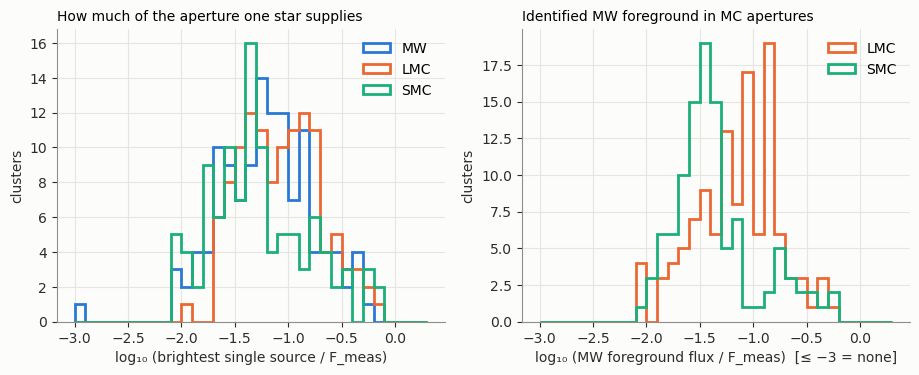

CONCLUSION —
  MW: one source supplies > 30% of F_meas in 7% of clusters; median 0.06
  LMC: one source supplies > 30% of F_meas in 8% of clusters; median 0.09 | foreground > 10% of F_meas in 36%
  SMC: one source supplies > 30% of F_meas in 8% of clusters; median 0.04 | foreground > 10% of F_meas in 17%


In [9]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
bins = np.linspace(-3, 0.3, 34)
for o in GAL:
    d = bud[bud.origin == o]
    axs[0].hist(np.log10(d.frac_brightest.clip(1e-3)), bins=bins, histtype='step', lw=2, color=COL[o], label=o)
    if o != 'MW':
        axs[1].hist(np.log10(d.frac_foreground.clip(1e-3)), bins=bins, histtype='step', lw=2, color=COL[o], label=o)
axs[0].set(xlabel='log₁₀ (brightest single source / F_meas)', ylabel='clusters')
axs[0].set_title('How much of the aperture one star supplies', loc='left', fontsize=10)
axs[1].set(xlabel='log₁₀ (MW foreground flux / F_meas)  [≤ −3 = none]', ylabel='clusters')
axs[1].set_title('Identified MW foreground in MC apertures', loc='left', fontsize=10)
axs[0].legend(); axs[1].legend(); save(fig, 'fig_lumpiness.png'); plt.show()

print('CONCLUSION —')
for o in GAL:
    d = bud[bud.origin == o]
    print(f'  {o}: one source supplies > 30% of F_meas in {np.mean(d.frac_brightest > .3):.0%} of clusters; '
          f'median {d.frac_brightest.median():.2f}'
          + (f' | foreground > 10% of F_meas in {np.mean(d.frac_foreground > .1):.0%}' if o != 'MW' else ''))

## 6 · Sky pedestal and sector-to-sector flux changes

If ELK's median flux kept the zodiacal light, its contribution is μ_zodi(β) × A_ap. An
additive background that hasn't been fully removed also changes from sector to sector (zodi
and scattered light depend on pointing and season), which would show up as `sector_spread`
being larger in apertures where the sky is a larger fraction of the flux.

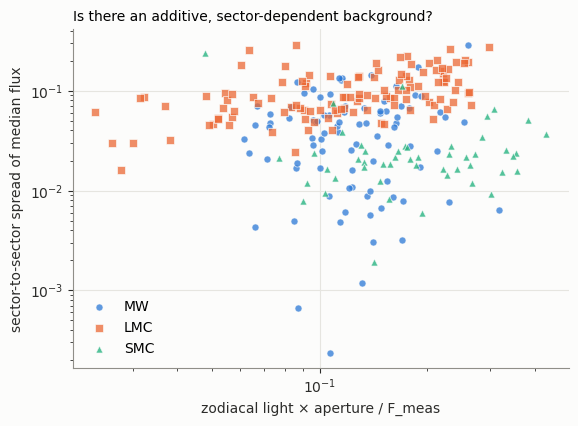

CONCLUSION —
  median zodi fraction: MW 0.121, LMC 0.129, SMC 0.152
  Spearman(sky fraction, sector spread) = +0.06 (p = 0.3, clusters with >1 sector)


In [10]:
bud['sky_frac'] = bud.F_sky / bud.F_meas
fig, ax = plt.subplots(figsize=(6.4, 4.4))
for o in GAL:
    d = bud[(bud.origin == o) & (bud.n_sectors > 1)]
    ax.scatter(d.sky_frac, d.sector_spread, s=26, marker=MRK[o], color=COL[o], alpha=.75,
               edgecolor='#fcfcfb', lw=.6, label=o)
ax.set(xscale='log', yscale='log', xlabel='zodiacal light × aperture / F_meas',
       ylabel='sector-to-sector spread of median flux')
ax.set_title('Is there an additive, sector-dependent background?', loc='left', fontsize=10)
ax.legend(); save(fig, 'fig_sky.png'); plt.show()
m = bud.n_sectors > 1
rho, p = stats.spearmanr(bud.sky_frac[m], bud.sector_spread[m], nan_policy='omit')
print('CONCLUSION —')
print(f'  median zodi fraction: ' + ', '.join(f'{o} {bud[bud.origin==o].sky_frac.median():.3f}' for o in GAL))
print(f'  Spearman(sky fraction, sector spread) = {rho:+.2f} (p = {p:.1g}, clusters with >1 sector)')

## 7 · Closure: does cluster + field add up to what ELK measured?

This test decides how to read everything else:
- $F_{\rm meas} \approx F_{\rm cl} + F_{\rm field}$: the field pedestal is in the light curve, so
  dilution applies.
- $F_{\rm meas} \approx F_{\rm cl}$: ELK's background step removed the mean level, and only
  field *variability* matters.

Model A (total field, including unresolved light) and Gaia B (resolved only) bracket the field.

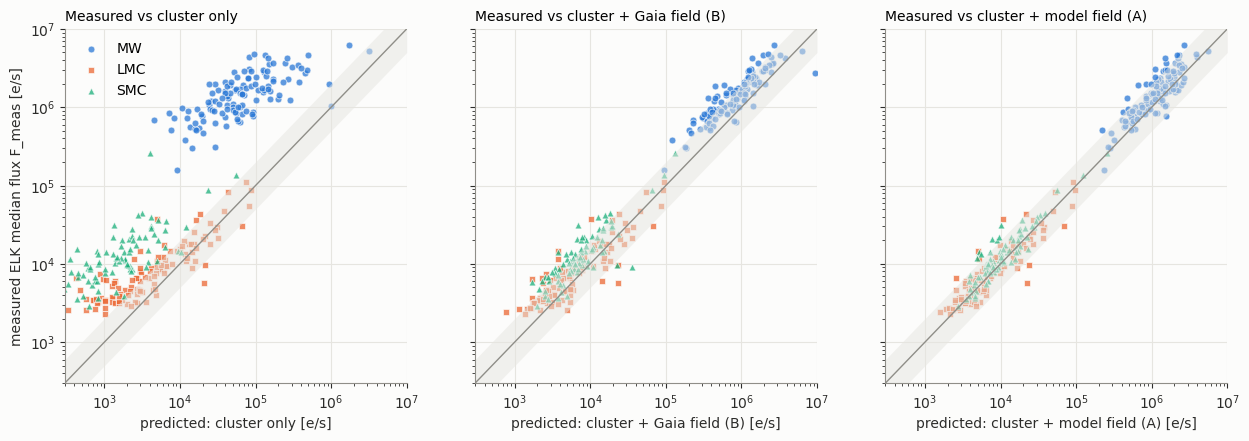

origin,MW,LMC,SMC
ratio,,,
F_meas / (F_cl + A + sky),1.11,0.89,0.97
F_meas / (F_cl + A),1.31,1.03,1.20
F_meas / (F_cl + B),1.69,1.28,1.73
F_meas / F_cl,23.16,1.93,7.44


origin,MW,LMC,SMC
ratio,,,
F_meas / (F_cl + A + sky),0.95,0.96,0.95
F_meas / (F_cl + A),0.89,0.93,0.92
F_meas / (F_cl + B),0.71,0.86,0.60
F_meas / F_cl,0.02,0.49,0.02


In [11]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
lim = np.array([3e2, 1e7])
for ax, (lab, pred) in zip(axs, [('cluster only', bud.F_cl),
                                 ('cluster + Gaia field (B)', bud.F_cl + bud.F_field_B),
                                 ('cluster + model field (A)', bud.F_cl + bud.F_field_A)]):
    for o in GAL:
        m = bud.origin == o
        ax.scatter(pred[m], bud.F_meas[m], s=24, marker=MRK[o], color=COL[o], alpha=.75,
                   edgecolor='#fcfcfb', lw=.6, label=o)
    ax.plot(lim, lim, color=MUTED, lw=1); ax.fill_between(lim, lim / 2, lim * 2, color='#e6e5e0', alpha=.5, lw=0)
    ax.set(xscale='log', yscale='log', xlim=lim, ylim=lim, xlabel=f'predicted: {lab} [e/s]')
    ax.set_title(f'Measured vs {lab}', loc='left', fontsize=10)
axs[0].set_ylabel('measured ELK median flux F_meas [e/s]'); axs[0].legend(loc='upper left')
save(fig, 'fig_closure.png'); plt.show()

rows = []
for o in GAL:
    d = bud[(bud.origin == o) & bud.F_cl.notna()]
    for lab, col in [('F_meas / F_cl', d.F_meas / d.F_cl), ('F_meas / (F_cl + B)', d.closure_B),
                     ('F_meas / (F_cl + A)', d.closure_A), ('F_meas / (F_cl + A + sky)', d.closure_A_sky)]:
        lr = np.log10(col.dropna())
        rows.append(dict(origin=o, ratio=lab, n=len(lr), median=10 ** lr.median(),
                         dex_scatter=0.5 * (lr.quantile(.84) - lr.quantile(.16)),
                         within_x2=np.mean(np.abs(lr) < np.log10(2))))
clo = pd.DataFrame(rows)
display(clo.pivot(index='ratio', columns='origin', values='median')[GAL].round(2))
display(clo.pivot(index='ratio', columns='origin', values='within_x2')[GAL].round(2))

### 7b · Is the ELK flux biased? Direct comparison with Gaia inside the aperture

The closure test above uses literature cluster light. A more direct check of the ELK flux
level (zero point, background handling) is to sum the TESS-band flux of **every Gaia source
inside the aperture** and compare it with $F_{\rm meas}$:

- **ELK below Gaia** would mean ELK loses flux: a zero-point error, over-subtracted
  background, or aperture losses.
- **ELK above Gaia** is expected from zodiacal light and from light Gaia doesn't resolve (stars
  fainter than G ≈ 20.7, blends in crowded fields and cluster cores). It could also come from
  an extra constant level that ELK keeps (residual scattered light, detector offsets).

The two explanations for an excess behave differently. A constant **pedestal** adds a roughly
fixed surface brightness per arcsec², so its fractional effect grows for fainter apertures and
shouldn't depend on the field density. **Missing stars** add light in proportion to the stellar
density, so the excess surface brightness should track the field surface brightness.

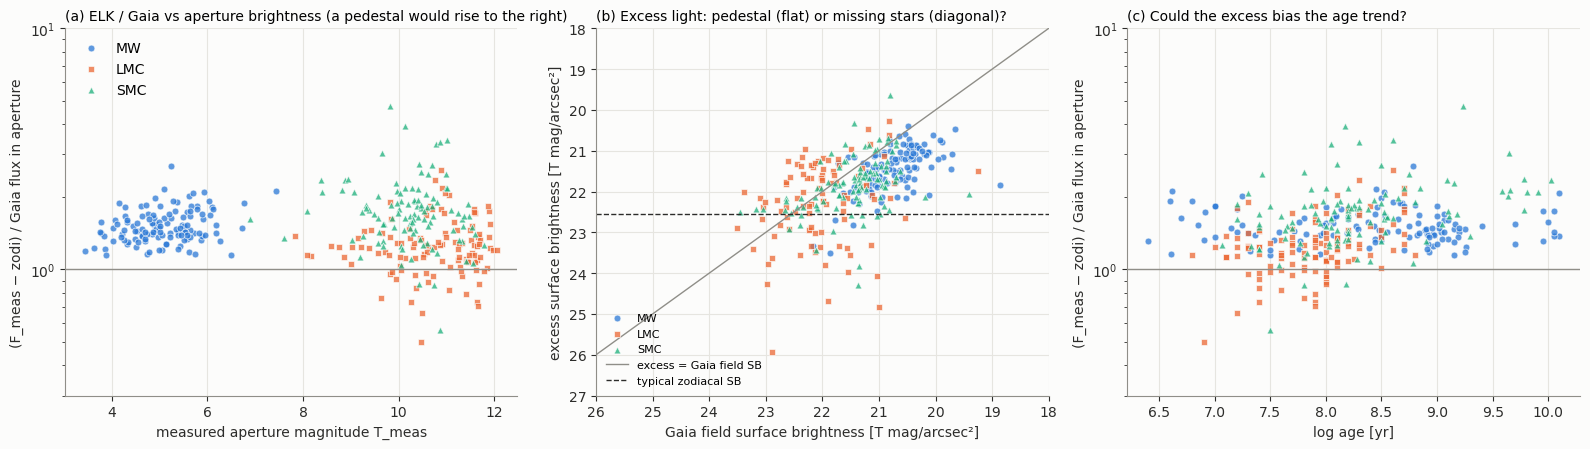

,n,ratio_median,ratio_16,ratio_84,frac_ELK_below_Gaia,rho_ratio_Tmeas,rho_ratio_age,rho_excessSB_fieldSB,excess_SB_mag,zodi_SB_mag
origin,,,,,,,,,,
MW,124,1.48,1.31,1.78,0.00,0.22,-0.10,0.57,21.40,22.37
LMC,118,1.24,0.99,1.58,0.10,0.04,0.34,0.24,22.17,22.64
SMC,106,1.70,1.31,2.17,0.03,-0.11,0.39,0.49,21.84,22.55


CONCLUSION —
  MW: ELK exceeds Gaia by x1.48 after zodi (ELK < Gaia in 0%); excess ~21.4 mag/arcsec2 vs zodi 22.4; rho(excess SB, field SB) = +0.57; rho(ratio, age) = -0.10
  LMC: ELK exceeds Gaia by x1.24 after zodi (ELK < Gaia in 10%); excess ~22.2 mag/arcsec2 vs zodi 22.6; rho(excess SB, field SB) = +0.24; rho(ratio, age) = +0.34
  SMC: ELK exceeds Gaia by x1.70 after zodi (ELK < Gaia in 3%); excess ~21.8 mag/arcsec2 vs zodi 22.6; rho(excess SB, field SB) = +0.49; rho(ratio, age) = +0.39
  ELK is not low relative to Gaia, so there is no sign of lost flux (zero point or over-subtraction).
  Any excess makes the denominator of f_cl too large, so f_cl errs low (conservative), by at most
  the ratio above.


In [12]:
bud['ratio_gaia'] = (bud.F_meas - bud.F_sky) / bud.F_gaia_in
bud['excess_sb'] = (bud.F_meas - bud.F_sky - bud.F_gaia_in) / bud.A_ap_arcsec2      # e/s/arcsec^2
mu = lambda f: -2.5 * np.log10(np.where(f > 0, f, np.nan)) + T_ZP                  # -> mag/arcsec^2

fig, axs = plt.subplots(1, 3, figsize=(16, 4.6))
for o in GAL:
    d = bud[bud.origin == o]
    kw = dict(s=24, marker=MRK[o], color=COL[o], alpha=.75, edgecolor='#fcfcfb', lw=.6, label=o)
    axs[0].scatter(d.T_meas, d.ratio_gaia, **kw)
    axs[1].scatter(mu(d.mu_B), mu(d.excess_sb), **kw)
    axs[2].scatter(d.age, d.ratio_gaia, **kw)
for ax in (axs[0], axs[2]):
    ax.axhline(1, color=MUTED, lw=1)
    ax.set(yscale='log', ylim=(0.3, 10))
axs[0].set(xlabel='measured aperture magnitude T_meas', ylabel='(F_meas − zodi) / Gaia flux in aperture')
axs[0].set_title('(a) ELK / Gaia vs aperture brightness (a pedestal would rise to the right)', loc='left', fontsize=10)
lim = np.array([18, 26])
axs[1].plot(lim, lim, color=MUTED, lw=1, label='excess = Gaia field SB')
axs[1].axhline(np.median(mu(M.zodi_sb(bud.ecl_lat))), color=INK, lw=1, ls='--', label='typical zodiacal SB')
axs[1].set(xlim=(26, 18), ylim=(27, 18), xlabel='Gaia field surface brightness [T mag/arcsec²]',
           ylabel='excess surface brightness [T mag/arcsec²]')
axs[1].set_title('(b) Excess light: pedestal (flat) or missing stars (diagonal)?', loc='left', fontsize=10)
axs[2].set(xlabel='log age [yr]', ylabel='(F_meas − zodi) / Gaia flux in aperture')
axs[2].set_title('(c) Could the excess bias the age trend?', loc='left', fontsize=10)
axs[0].legend(loc='upper left'); axs[1].legend(loc='lower left', fontsize=8)
fig.tight_layout(); save(fig, 'fig_elk_vs_gaia.png'); plt.show()

rows = []
for o in GAL:
    d = bud[bud.origin == o]
    r = d.ratio_gaia
    ok = d.excess_sb > 0
    rows.append(dict(origin=o, n=len(d),
                     ratio_median=r.median(), ratio_16=r.quantile(.16), ratio_84=r.quantile(.84),
                     frac_ELK_below_Gaia=np.mean(d.F_meas < d.F_gaia_in),
                     rho_ratio_Tmeas=stats.spearmanr(r, d.T_meas)[0],
                     rho_ratio_age=stats.spearmanr(r, d.age)[0],
                     rho_excessSB_fieldSB=stats.spearmanr(d.excess_sb[ok], d.mu_B[ok])[0],
                     excess_SB_mag=np.nanmedian(mu(d.excess_sb[ok])),
                     zodi_SB_mag=np.median(mu(M.zodi_sb(d.ecl_lat)))))
gx = pd.DataFrame(rows).set_index('origin')
display(gx.round(2))

print('CONCLUSION —')
for o in GAL:
    g = gx.loc[o]
    print(f'  {o}: ELK exceeds Gaia by x{g.ratio_median:.2f} after zodi (ELK < Gaia in {g.frac_ELK_below_Gaia:.0%}); '
          f'excess ~{g.excess_SB_mag:.1f} mag/arcsec2 vs zodi {g.zodi_SB_mag:.1f}; '
          f'rho(excess SB, field SB) = {g.rho_excessSB_fieldSB:+.2f}; rho(ratio, age) = {g.rho_ratio_age:+.2f}')
print('  ELK is not low relative to Gaia, so there is no sign of lost flux (zero point or over-subtraction).')
print('  Any excess makes the denominator of f_cl too large, so f_cl errs low (conservative), by at most')
print('  the ratio above.')

**Reading the three panels:**
- **(a) No sign of a pedestal.** ELK sits 1.2–1.7× above Gaia, and that ratio barely changes with
  aperture brightness (ρ ≈ +0.2 MW, ≈ 0 LMC and SMC). A constant added level would make faint
  apertures stand out. ELK is never systematically below Gaia, so there's no sign of lost flux
  from the zero point or over-subtraction.
- **(b) The excess follows the field.** The excess surface brightness tracks the Gaia field surface
  brightness (ρ ≈ +0.2 to +0.6) and sits near the 1:1 line, not on a flat line. So it behaves
  like real stellar light Gaia doesn't resolve (faint stars, blends in crowded fields), which
  legitimately belongs in the denominator, and not like an instrumental offset. It is also
  comparable to or brighter than the zodiacal level.
- **(c) A mild age dependence in the Clouds** (ρ ≈ +0.35 to +0.4): older clusters' apertures have
  relatively more unresolved light. Because that light is real, it is part of the dilution
  rather than a bias in f_cl. If part of it were instrumental, the effect on the f_cl–age slope
  would be at most ~0.15 dex across the LMC age range, against an observed ~1 dex.

## 8 · The answer: f_cl, and whether it depends on age

The adopted value is $f_{\rm cl} = F_{\rm cl,phot}/F_{\rm meas}$: literature cluster light over
the *measured* aperture flux. The denominator is empirical, so this doesn't depend on either
field model. Error bars span the photometry, mass and Gaia routes plus the enclosure range.
Values above 1 mean the literature/PSF estimate of cluster light exceeds the measured flux; for
an order-of-magnitude result that is an error-bar statement (part of the light removed by ELK's
background step, or a catalogue aperture larger than ELK's), not a physical fraction.

The **second row** removes the zodiacal pedestal from the denominator: cluster / (F_meas − zodi).
ELK keeps the sky's constant level (Section 6), but the sky doesn't vary on the timescales the
statistics probe, so this ratio is the cluster's share of the light that *can* carry variability
(cluster + field stars). Clusters where the sky model exceeds half of F_meas are left out.

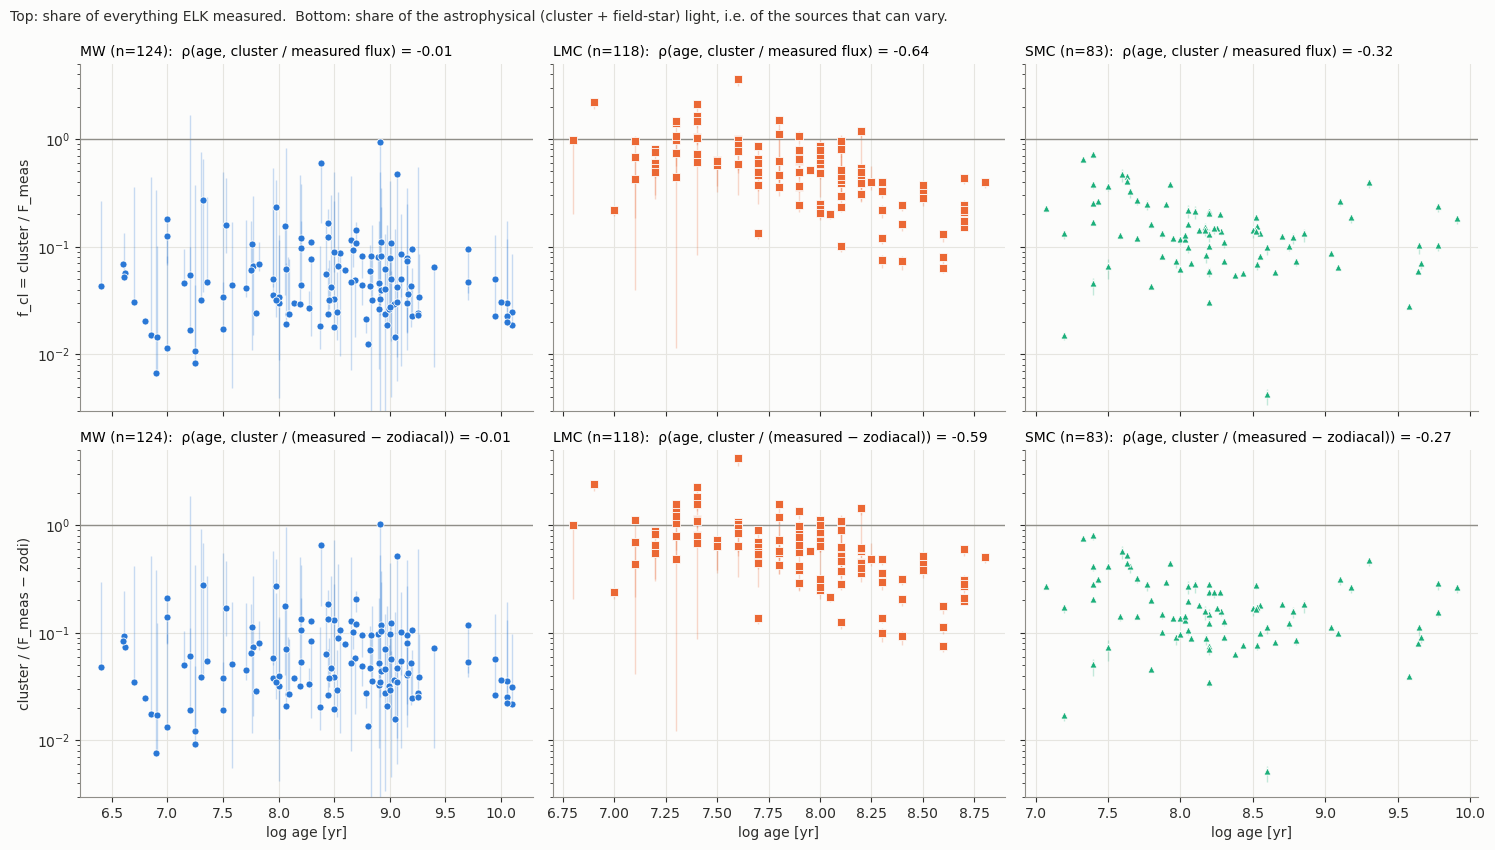

In [13]:
ROWS = [('f_cl', 'cluster / measured flux', 'f_cl = cluster / F_meas'),
        ('f_cl_astro', 'cluster / (measured − zodiacal)', 'cluster / (F_meas − zodi)')]
fig, axs = plt.subplots(2, 3, figsize=(15, 8.6), sharey=True, sharex='col')
for r, (col, lab, ylab) in enumerate(ROWS):
    for ax, o in zip(axs[r], GAL):
        d = bud[(bud.origin == o) & bud[col].notna()]
        yerr = np.array([d[col] - d[col + '_lo'], d[col + '_hi'] - d[col]]).clip(0)
        ax.errorbar(d.age, d[col], yerr=yerr, fmt='none', ecolor=COL[o], alpha=.25, lw=1)
        ax.scatter(d.age, d[col], s=26, marker=MRK[o], color=COL[o], edgecolor='#fcfcfb', lw=.6, zorder=3)
        rho = stats.spearmanr(d.age, d[col])[0]
        ax.axhline(1, color=MUTED, lw=1)
        ax.set(yscale='log', ylim=(3e-3, 5))
        ax.set_title(f'{o} (n={len(d)}):  ρ(age, {lab}) = {rho:+.2f}', loc='left', fontsize=10)
        if r == 1:
            ax.set_xlabel('log age [yr]')
    axs[r, 0].set_ylabel(ylab)
fig.text(0.005, 0.97, 'Top: share of everything ELK measured.  Bottom: share of the astrophysical '
         '(cluster + field-star) light, i.e. of the sources that can vary.', fontsize=10, color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.96))
save(fig, 'fig_fcl_vs_age.png'); plt.show()

In [14]:
sys.path.insert(0, os.path.join(C.LC_DIR, '..', 'Correlation_Analysis'))
import analysis_utils as A

res = []
for col in ('f_cl', 'f_cl_astro'):
    for o in GAL + ['all']:
        d = bud[bud[col].notna()] if o == 'all' else bud[(bud.origin == o) & bud[col].notna()]
        rho, p, (lo, hi) = A.spearman_ci(np.log10(d[col]), d.age, n_boot=1000, seed=0)
        res.append(dict(quantity=col, subset=o, n=len(d), median_f_cl=d[col].median(),
                        f_cl_16=d[col].quantile(.16), f_cl_84=d[col].quantile(.84),
                        rho_age=rho, lo=lo, hi=hi, p=p))
fcl_age_all = pd.DataFrame(res)
display(fcl_age_all.round(3))
fcl_age = fcl_age_all[fcl_age_all.quantity == 'f_cl']

,quantity,subset,n,median_f_cl,f_cl_16,f_cl_84,rho_age,lo,hi,p
0,f_cl,MW,124,0.043,0.023,0.096,-0.009,-0.192,0.164,0.925
1,f_cl,LMC,118,0.518,0.242,0.968,-0.644,-0.742,-0.519,0.000
2,f_cl,SMC,83,0.134,0.066,0.256,-0.319,-0.538,-0.098,0.003
3,f_cl,all,325,0.134,0.033,0.610,-0.407,-0.511,-0.296,0.000
4,f_cl_astro,MW,124,0.049,0.026,0.115,-0.009,-0.192,0.163,0.924
5,f_cl_astro,LMC,118,0.617,0.295,1.044,-0.590,-0.700,-0.455,0.000
6,f_cl_astro,SMC,83,0.158,0.083,0.293,-0.272,-0.501,-0.046,0.013
7,f_cl_astro,all,325,0.158,0.038,0.685,-0.393,-0.500,-0.283,0.000


### 8a · What could dilution do to the amplitude–age trend?

This compares f_cl with the variability amplitude from the correlation table (median over a
cluster's sector combinations, log₁₀ of `intrinsic_std`). If quiet field light dominates the
denominator, then $\log a_{\rm obs} = \log a_{\rm cl} + \log f_{\rm cl}$, and
$\log a_{\rm obs} - \log f_{\rm cl}$ is the dilution-corrected amplitude. This is
**descriptive**: it shows how much of the raw amplitude–age correlation dilution could carry.
It is not a nuisance-controlled re-test, which is the planned next step.

matched 348 of 348 clusters to the correlation table


,subset,n,rho_amp_fcl,ci_amp_fcl,rho_amp_age_raw,ci_raw,rho_amp_age_corrected,ci_corr
0,MW,124,0.12,"[-0.07, +0.29]",-0.30,"[-0.45, -0.12]",-0.24,"[-0.39, -0.08]"
1,LMC,118,0.26,"[+0.09, +0.43]",-0.25,"[-0.42, -0.07]",0.25,"[+0.09, +0.41]"
2,SMC,77,0.23,"[+0.01, +0.45]",-0.15,"[-0.36, +0.07]",0.09,"[-0.16, +0.32]"
3,all,319,0.50,"[+0.41, +0.57]",-0.37,"[-0.47, -0.27]",0.14,"[+0.03, +0.25]"


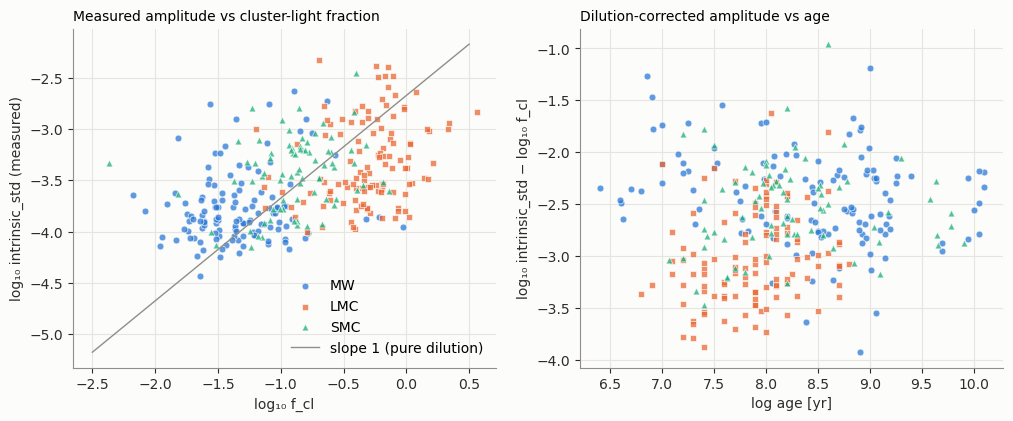

In [15]:
GT = os.path.join(C.LC_DIR, '..', 'GenerateTable_CGW', 'data')
rows = A.load_rows(os.path.join(GT, 'cluster_table_Sep23_all_combos_le3sectors.pkl'), verbose=False)
ct = A.cluster_table(rows)[['name', 'intrinsic_std', 'sigma_mad']]
j = bud.merge(ct, on='name', how='inner')
print(f'matched {len(j)} of {len(bud)} clusters to the correlation table')
j['log_fcl'] = np.log10(j.f_cl)
j['amp_corr'] = j.intrinsic_std - j.log_fcl          # intrinsic_std is already log10 there

out = []
for o in GAL + ['all']:
    d = j if o == 'all' else j[j.origin == o]
    d = d[np.isfinite(d.log_fcl) & np.isfinite(d.intrinsic_std)]
    r_af = A.spearman_ci(d.intrinsic_std, d.log_fcl, n_boot=1000, seed=0)
    r_raw = A.spearman_ci(d.intrinsic_std, d.age, n_boot=1000, seed=0)
    r_cor = A.spearman_ci(d.amp_corr, d.age, n_boot=1000, seed=0)
    out.append(dict(subset=o, n=len(d),
                    rho_amp_fcl=r_af[0], ci_amp_fcl=f'[{r_af[2][0]:+.2f}, {r_af[2][1]:+.2f}]',
                    rho_amp_age_raw=r_raw[0], ci_raw=f'[{r_raw[2][0]:+.2f}, {r_raw[2][1]:+.2f}]',
                    rho_amp_age_corrected=r_cor[0], ci_corr=f'[{r_cor[2][0]:+.2f}, {r_cor[2][1]:+.2f}]'))
dil = pd.DataFrame(out)
display(dil.round(2))

fig, axs = plt.subplots(1, 2, figsize=(12, 4.4))
for o in GAL:
    d = j[j.origin == o]
    axs[0].scatter(d.log_fcl, d.intrinsic_std, s=24, marker=MRK[o], color=COL[o], alpha=.75,
                   edgecolor='#fcfcfb', lw=.6, label=o)
    axs[1].scatter(d.age, d.amp_corr, s=24, marker=MRK[o], color=COL[o], alpha=.75,
                   edgecolor='#fcfcfb', lw=.6, label=o)
x = np.array([-2.5, 0.5]); axs[0].plot(x, x + np.nanmedian(j.amp_corr), color=MUTED, lw=1, label='slope 1 (pure dilution)')
axs[0].set(xlabel='log₁₀ f_cl', ylabel='log₁₀ intrinsic_std (measured)')
axs[0].set_title('Measured amplitude vs cluster-light fraction', loc='left', fontsize=10)
axs[1].set(xlabel='log age [yr]', ylabel='log₁₀ intrinsic_std − log₁₀ f_cl')
axs[1].set_title('Dilution-corrected amplitude vs age', loc='left', fontsize=10)
axs[0].legend(); save(fig, 'fig_dilution_amplitude.png'); plt.show()

## 9 · Conclusions and limitations

In [16]:
def line(o):
    r = fcl_age.set_index('subset').loc[o]
    return (f'{o:>4s}: median f_cl = {r.median_f_cl:.2f} (16-84%: {r.f_cl_16:.2f}-{r.f_cl_84:.2f}); '
            f'rho(age, log f_cl) = {r.rho_age:+.2f} [{r.lo:+.2f}, {r.hi:+.2f}]')
print('CONCLUSION —')
for o in GAL + ['all']:
    print('  ' + line(o))
c = clo.set_index(['ratio', 'origin'])['median']
print('  closure, median F_meas/(F_cl+B): ' + ', '.join(f'{o} {c[("F_meas / (F_cl + B)", o)]:.2f}' for o in GAL))
d = dil.set_index('subset')
print('  amplitude-age rho, raw -> dilution-corrected: ' +
      ', '.join(f'{o} {d.loc[o, "rho_amp_age_raw"]:+.2f} -> {d.loc[o, "rho_amp_age_corrected"]:+.2f}' for o in GAL + ['all']))

CONCLUSION —
    MW: median f_cl = 0.04 (16-84%: 0.02-0.10); rho(age, log f_cl) = -0.01 [-0.19, +0.16]
   LMC: median f_cl = 0.52 (16-84%: 0.24-0.97); rho(age, log f_cl) = -0.64 [-0.74, -0.52]
   SMC: median f_cl = 0.13 (16-84%: 0.07-0.26); rho(age, log f_cl) = -0.32 [-0.54, -0.10]
   all: median f_cl = 0.13 (16-84%: 0.03-0.61); rho(age, log f_cl) = -0.41 [-0.51, -0.30]
  closure, median F_meas/(F_cl+B): MW 1.69, LMC 1.28, SMC 1.73
  amplitude-age rho, raw -> dilution-corrected: MW -0.30 -> -0.24, LMC -0.25 -> +0.25, SMC -0.15 -> +0.09, all -0.37 -> +0.14


**What the numbers say** (values from the cells above):

1. **The budget closes, and the field pedestal is in the light curves.** Literature cluster
   light + smooth field model + zodiacal light reproduces the measured ELK median flux to a
   median of 0.9–1.1 in all three galaxies, with ~95% of clusters within a factor of 2. Leaving
   out the field (F_meas/F_cl ≈ 2–20) fails badly. So ELK's background step removes the
   *variations*, not the mean level, and every normalised statistic is divided by
   cluster + field + sky.
2. **Most of the light in most apertures isn't the cluster.** Median f_cl is ≈ 0.04 in the MW
   (the 9′-radius r₂ apertures in the disk are ~96% field; the Gaia route would raise this by
   ~2.5×, still ≲ 0.1), ≈ 0.13 in the SMC, and ≈ 0.5 in the LMC. About 8% of clusters have a
   single star supplying > 30% of the aperture flux.
3. **In the Magellanic Clouds, dilution depends on age.** ρ(age, log f_cl) ≈ −0.64 (LMC) and
   −0.32 (SMC): older clusters are fainter and therefore more diluted, as the M/L argument
   predicts. In the MW there is no dependence (≈ 0), because dilution is uniformly severe.
4. **Consequence for the amplitude–age trend.** In the LMC the measured amplitude tracks
   f_cl, and dividing out dilution reverses the amplitude–age correlation (−0.25 → +0.25). In the
   SMC it becomes consistent with zero. In the MW the trend is essentially unchanged
   (−0.30 → −0.24). So:
   - the *Magellanic-Cloud* "younger clusters vary more" signal is consistent with being
     produced by age-dependent dilution;
   - the full correction probably *over*-corrects, since it assigns all variance to the
     cluster, but variable field stars add variance that is magnified when f_cl is small.
     The true intrinsic relation lies between the raw and corrected values;
   - the *MW* trend isn't explained by dilution, but MW apertures are ~96% field, so MW
     variability statistics mostly describe the field population along the line of sight.
5. **Next step (not done here):** add log f_cl, and the field surface brightness, to the
   nuisance set in `Correlation_Analysis/` and re-run the partial correlations and ridge tests.

> **NOTE — aperture radii vs literature photometry (found Oct 6 2026; not yet acted on).**
> Radius check, cluster by cluster:
> - **MW:** ELK r = Kharchenko 2013 r₂ (124/124).
> - **LMC:** ELK r = Glatt R_app (118/118).
> - **SMC:** ELK r = Bica 2020 *mean axis*. Bica's axes are **diameters**, so ELK's SMC apertures
>   are 2× the intended radius (4× the area). Glatt's SMC photometry used the true radius,
>   r_ELK/2.
>
> Consequences:
> 1. **Cluster light is underestimated slightly.** The current code treats Glatt's SMC radius as
>    equal to ELK's, which underestimates SMC cluster light by ≈ ×1.10 (+0.04 dex; median SMC
>    f_cl 0.135 → 0.149 if corrected).
> 2. **The field light is real.** The extra field in the 4×-area apertures really is in the ELK
>    light curves, so it is real dilution and largely explains why SMC f_cl ≪ LMC f_cl.
> 3. **The aperture doubling affects selection.** With the true radius, 69 of the 106 SMC
>    clusters would fail ELK's r > 0.01° (one TESS pixel) cut.
>
> The enclosure fix in `crowd/budget.py` has not been made yet; it is deliberately deferred.

**Limitations**, roughly in order of importance:
1. **Stochastic sampling.** Most clusters here are ≲ 10⁴ M☉, so a few supergiants or giants
   carry much of their light. This affects both the literature photometry (field subtraction
   of one or two bright stars) and the mass route (expectation vs realisation).
2. **Catalogue apertures.** Glatt's R_app equals the ELK radius and Kharchenko's r₂ equals the
   MW radius. Rafelski's photometric apertures differ from the Bica 2020 radii ELK used for the
   SMC.
3. **Pixelised aperture.** ELK sums whole pixels. At r_ap ≈ 2 px the true aperture area can
   differ from πr² by ±20%, which scales every field estimate by the same factor.
4. **Model A is smooth.** It has no LMC bar (underestimating the bar region by ~2×), no
   star-forming complexes, and a crude MW dust layer.
5. **Gaia B is incomplete.** It misses the unresolved field main sequence in the MCs and
   suffers crowding incompleteness inside dense cluster cores.
6. **Background subtraction in ELK** is not modelled. The closure test measures its net effect
   on the mean level instead.